# Bitcoin Market & Macroeconomic Analysis (Oct 2025 – Sep 2026)

**Research question:** How do macroeconomic conditions and traditional financial markets relate to Bitcoin's price movements?

- **H1:** Bitcoin and S&P 500 daily returns are positively correlated.
- **H2:** Changes in the Effective Federal Funds Rate are associated with Bitcoin's daily returns.
- **H3:** U.S. inflation is associated with Bitcoin's monthly returns.

**Data Sources**

Bitcoin historical price data was downloaded from CoinGecko on October 15, 2026 (`btc-usd-max.csv`). S&P 500 prices, the Effective Federal Funds Rate, and CPI data were obtained from Federal Reserve Economic Data (FRED). To run this notebook, download the four CSV datasets and place them in the working directory (or upload them to the Colab session). GitHub does not automatically provide the data files; see the README for setup instructions.

The full write-up is in the accompanying PDF report.

## 1. Load and filter the Bitcoin data

### Running this notebook

I used Python in Google Colab for the analysis. The notebook expects `btc-usd-max.csv`, `SP500.csv`, `DFF.csv`, and `CPIAUCSL.csv` in its working directory. If you're running it in a new Colab session, upload those files first. Run the cells from top to bottom; the notebook also saves a few figures and a results table.

The notebook uses **same-day market relationships**, so the regression results should not be treated as a Bitcoin price forecast.

In [1]:
import pandas as pd

btc = pd.read_csv("btc-usd-max.csv")

print(btc.head())


                event_date  close_price_usd  market_cap_usd  volume_usd
0  2013-04-28 00:00:00 UTC           141.96    1.500518e+09         0.0
1  2013-04-29 00:00:00 UTC           135.30    1.575032e+09         0.0
2  2013-04-30 00:00:00 UTC           117.00    1.501657e+09         0.0
3  2013-05-01 00:00:00 UTC           103.43    1.298952e+09         0.0
4  2013-05-02 00:00:00 UTC            91.01    1.148668e+09         0.0


In [2]:
print(btc.shape)
print(btc.columns)


(4919, 4)
Index(['event_date', 'close_price_usd', 'market_cap_usd', 'volume_usd'], dtype='object')


In [3]:
btc["event_date"] = pd.to_datetime(btc["event_date"], utc=True)

btc_filtered = btc[
    (btc["event_date"] >= "2025-10-01") &
    (btc["event_date"] < "2026-10-01")
]

print(btc_filtered.head())
print(btc_filtered.shape)


                    event_date  close_price_usd  market_cap_usd    volume_usd
4539 2025-10-01 00:00:00+00:00    118930.955114    2.273504e+12  5.750203e+10
4540 2025-10-02 00:00:00+00:00    120514.577856    2.362726e+12  7.111568e+10
4541 2025-10-03 00:00:00+00:00    122294.924417    2.404249e+12  7.070886e+10
4542 2025-10-04 00:00:00+00:00    122428.890634    2.437131e+12  8.267154e+10
4543 2025-10-05 00:00:00+00:00    123488.730597    2.438832e+12  3.484944e+10
(365, 4)


## 2. Bitcoin price performance and volatility

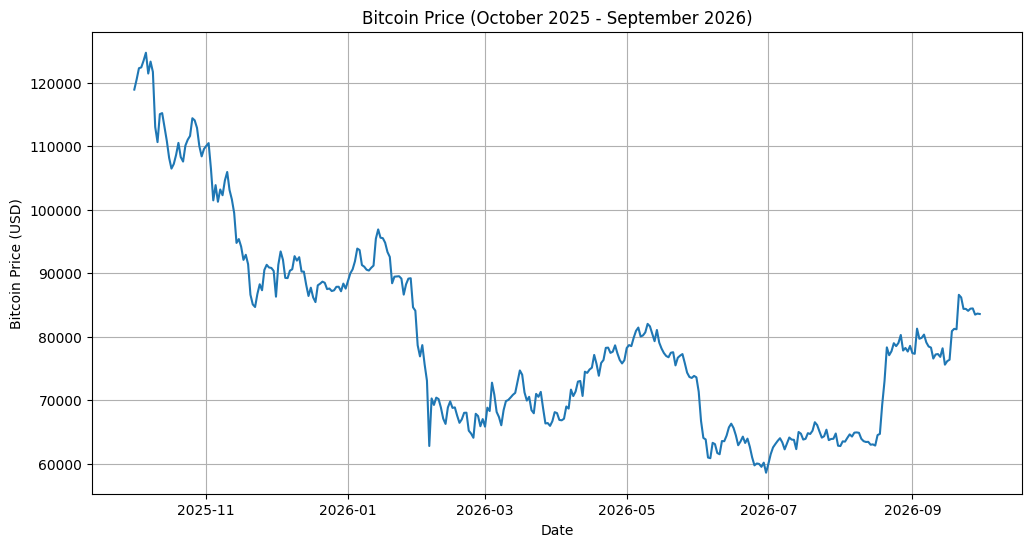

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(btc_filtered["event_date"], btc_filtered["close_price_usd"])

plt.title("Bitcoin Price (October 2025 - September 2026)")
plt.xlabel("Date")
plt.ylabel("Bitcoin Price (USD)")

plt.grid(True)
plt.show()


In [5]:
starting_price = btc_filtered["close_price_usd"].iloc[0]

ending_price = btc_filtered["close_price_usd"].iloc[-1]

total_return = ((ending_price - starting_price) / starting_price) * 100

print("Starting Bitcoin Price:", starting_price)
print("Ending Bitcoin Price:", ending_price)
print("Total Return (%):", total_return)


Starting Bitcoin Price: 118930.95511416093
Ending Bitcoin Price: 83576.13460018387
Total Return (%): -29.727181186798873


In [6]:
btc_filtered = btc_filtered.copy()

btc_filtered["daily_return"] = btc_filtered["close_price_usd"].pct_change() * 100

print(btc_filtered[["event_date", "close_price_usd", "daily_return"]].head())


                    event_date  close_price_usd  daily_return
4539 2025-10-01 00:00:00+00:00    118930.955114           NaN
4540 2025-10-02 00:00:00+00:00    120514.577856      1.331548
4541 2025-10-03 00:00:00+00:00    122294.924417      1.477287
4542 2025-10-04 00:00:00+00:00    122428.890634      0.109544
4543 2025-10-05 00:00:00+00:00    123488.730597      0.865678


In [7]:
daily_volatility = btc_filtered["daily_return"].std()

annual_volatility = daily_volatility * (365 ** 0.5)

print("Daily Volatility (%):", daily_volatility)
print("Annualized Volatility (%):", annual_volatility)


Daily Volatility (%): 2.3380236122031706
Annualized Volatility (%): 44.66787839258923


In [8]:
best_day = btc_filtered.loc[btc_filtered["daily_return"].idxmax()]

worst_day = btc_filtered.loc[btc_filtered["daily_return"].idxmin()]

print("Best Day:", best_day["event_date"])
print("Best Daily Return (%):", best_day["daily_return"])

print("Worst Day:", worst_day["event_date"])
print("Worst Daily Return (%):", worst_day["daily_return"])


Best Day: 2026-02-06 00:00:00+00:00
Best Daily Return (%): 11.937746810242267
Worst Day: 2026-02-05 00:00:00+00:00
Worst Daily Return (%): -14.072101985649432


## 3. Bitcoin vs. the S&P 500

The S&P 500 only trades on market days, so I match Bitcoin to S&P 500 dates and calculate returns between matched dates.

In [9]:
sp500 = pd.read_csv("SP500.csv")

print(sp500.head())
print(sp500.shape)
print(sp500.columns)


  observation_date    SP500
0       2025-10-13  6654.72
1       2025-10-14  6644.31
2       2025-10-15  6671.06
3       2025-10-16  6629.07
4       2025-10-17  6664.01
(253, 2)
Index(['observation_date', 'SP500'], dtype='object')


In [10]:
sp500["observation_date"] = pd.to_datetime(sp500["observation_date"], utc=True)

print(sp500.head())
print(sp500.dtypes)


           observation_date    SP500
0 2025-10-13 00:00:00+00:00  6654.72
1 2025-10-14 00:00:00+00:00  6644.31
2 2025-10-15 00:00:00+00:00  6671.06
3 2025-10-16 00:00:00+00:00  6629.07
4 2025-10-17 00:00:00+00:00  6664.01
observation_date    datetime64[ns, UTC]
SP500                           float64
dtype: object


In [11]:
combined = pd.merge(
    btc_filtered,
    sp500,
    left_on="event_date",
    right_on="observation_date",
    how="inner"
)

print(combined.head())
print(combined.shape)


                 event_date  close_price_usd  market_cap_usd    volume_usd  \
0 2025-10-13 00:00:00+00:00    115226.584290    2.296145e+12  9.470878e+10   
1 2025-10-14 00:00:00+00:00    113066.350785    2.297230e+12  6.976398e+10   
2 2025-10-15 00:00:00+00:00    110844.404172    2.255594e+12  9.086941e+10   
3 2025-10-16 00:00:00+00:00    108168.173534    2.207806e+12  6.912243e+10   
4 2025-10-17 00:00:00+00:00    106483.891436    2.154965e+12  8.408209e+10   

   daily_return          observation_date    SP500  
0      0.144011 2025-10-13 00:00:00+00:00  6654.72  
1     -1.874770 2025-10-14 00:00:00+00:00  6644.31  
2     -1.965171 2025-10-15 00:00:00+00:00  6671.06  
3     -2.414403 2025-10-16 00:00:00+00:00  6629.07  
4     -1.557096 2025-10-17 00:00:00+00:00  6664.01  
(253, 7)


In [12]:
combined["btc_return"] = combined["close_price_usd"].pct_change() * 100

combined["sp500_return"] = combined["SP500"].pct_change() * 100

print(combined[["event_date", "btc_return", "sp500_return"]].head(10))

                 event_date  btc_return  sp500_return
0 2025-10-13 00:00:00+00:00         NaN           NaN
1 2025-10-14 00:00:00+00:00   -1.874770     -0.156430
2 2025-10-15 00:00:00+00:00   -1.965171      0.402600
3 2025-10-16 00:00:00+00:00   -2.414403     -0.629435
4 2025-10-17 00:00:00+00:00   -1.557096      0.527072
5 2025-10-20 00:00:00+00:00    3.805244      1.067225
6 2025-10-21 00:00:00+00:00   -2.021162      0.003266
7 2025-10-22 00:00:00+00:00   -0.655847     -0.533751
8 2025-10-23 00:00:00+00:00    2.340190      0.582739
9 2025-10-24 00:00:00+00:00    0.836331      0.790242


/tmp/ipykernel_4128/1838279644.py:3: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  combined["sp500_return"] = combined["SP500"].pct_change() * 100


In [13]:
correlation = combined["btc_return"].corr(combined["sp500_return"])

print("Bitcoin vs S&P 500 Correlation:", correlation)

Bitcoin vs S&P 500 Correlation: 0.4562451557326033


### Fixing missing holiday prices

My first return calculation (above) gave a correlation of about 0.456, but pandas showed a warning that it was filling in missing values. The S&P 500 file has no price on 10 market holidays, and those gaps were being filled with the previous day's price, which treated holidays as zero-return days. Below I list the missing dates, drop them, and recalculate both returns without filling. The correlation changes to about 0.470.

In [14]:
print("Missing S&P 500 values:", combined ["SP500"].isna().sum())

print("Missing Bitcoin values:", combined["close_price_usd"].isna().sum())


Missing S&P 500 values: 10
Missing Bitcoin values: 0


In [15]:
missing_sp500 = combined[
    combined["SP500"].isna()
][["event_date", "close_price_usd", "SP500"]]

print("Dates with missing S&P 500 prices:")
print(missing_sp500.to_string(index=False))

print("\nTotal missing dates:", len(missing_sp500))


Dates with missing S&P 500 prices:
               event_date  close_price_usd  SP500
2025-11-27 00:00:00+00:00     91323.628276    NaN
2025-12-25 00:00:00+00:00     87192.234737    NaN
2026-01-01 00:00:00+00:00     88764.126241    NaN
2026-01-19 00:00:00+00:00     92566.012780    NaN
2026-02-16 00:00:00+00:00     68859.776187    NaN
2026-04-03 00:00:00+00:00     66822.552303    NaN
2026-05-25 00:00:00+00:00     77258.399124    NaN
2026-06-19 00:00:00+00:00     63489.810948    NaN
2026-07-03 00:00:00+00:00     62553.612892    NaN
2026-09-07 00:00:00+00:00     79093.464190    NaN

Total missing dates: 10


In [16]:
combined_clean = combined.dropna(subset=["SP500", "close_price_usd"]).copy()

print("Original rows:", combined.shape[0])
print("Clean rows:", combined_clean.shape[0])


Original rows: 253
Clean rows: 243


In [17]:
combined_clean["btc_return"] = combined_clean["close_price_usd"].pct_change(fill_method=None) * 100

combined_clean["sp500_return"] = combined_clean["SP500"].pct_change(fill_method=None) * 100

correlation_clean = combined_clean["btc_return"].corr(combined_clean["sp500_return"])

print("Cleaned Correlation:", correlation_clean)


Cleaned Correlation: 0.4704285020121105


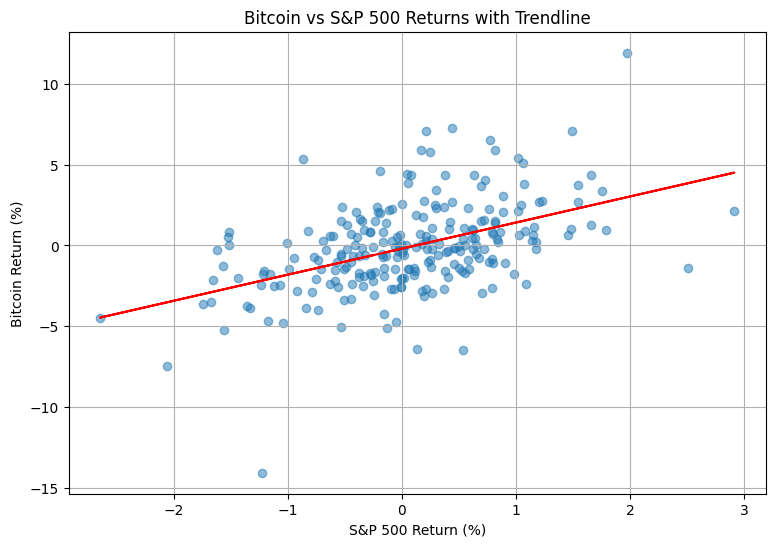

In [18]:
import numpy as np
import matplotlib.pyplot as plt

x = combined_clean["sp500_return"].dropna()
y = combined_clean.loc[x.index, "btc_return"]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(9, 6))
plt.scatter(x, y, alpha=0.5)
plt.plot(x, slope * x + intercept, color="red")

plt.title("Bitcoin vs S&P 500 Returns with Trendline")
plt.xlabel("S&P 500 Return (%)")
plt.ylabel("Bitcoin Return (%)")
plt.grid(True)
plt.show()


## 4. Bitcoin vs. the Federal Funds Rate

The chart below is for visual context only. Correlating two trending price levels can be misleading, so the actual test uses daily returns vs. daily rate changes.

In [19]:
import pandas as pd

fed = pd.read_csv("DFF.csv")

print(fed.head())
print(fed.shape)
print(fed.columns)


  observation_date   DFF
0       2025-10-01  4.09
1       2025-10-02  4.09
2       2025-10-03  4.09
3       2025-10-04  4.09
4       2025-10-05  4.09
(365, 2)
Index(['observation_date', 'DFF'], dtype='object')


In [20]:
fed["observation_date"] = pd.to_datetime(fed["observation_date"], utc=True)

print(fed.dtypes)
print(fed.head())


observation_date    datetime64[ns, UTC]
DFF                             float64
dtype: object
           observation_date   DFF
0 2025-10-01 00:00:00+00:00  4.09
1 2025-10-02 00:00:00+00:00  4.09
2 2025-10-03 00:00:00+00:00  4.09
3 2025-10-04 00:00:00+00:00  4.09
4 2025-10-05 00:00:00+00:00  4.09


In [21]:
btc_fed = pd.merge(
    btc_filtered,
    fed,
    left_on="event_date",
    right_on="observation_date",
    how="inner"
)

print(btc_fed.head())
print(btc_fed.shape)


                 event_date  close_price_usd  market_cap_usd    volume_usd  \
0 2025-10-01 00:00:00+00:00    118930.955114    2.273504e+12  5.750203e+10   
1 2025-10-02 00:00:00+00:00    120514.577856    2.362726e+12  7.111568e+10   
2 2025-10-03 00:00:00+00:00    122294.924417    2.404249e+12  7.070886e+10   
3 2025-10-04 00:00:00+00:00    122428.890634    2.437131e+12  8.267154e+10   
4 2025-10-05 00:00:00+00:00    123488.730597    2.438832e+12  3.484944e+10   

   daily_return          observation_date   DFF  
0           NaN 2025-10-01 00:00:00+00:00  4.09  
1      1.331548 2025-10-02 00:00:00+00:00  4.09  
2      1.477287 2025-10-03 00:00:00+00:00  4.09  
3      0.109544 2025-10-04 00:00:00+00:00  4.09  
4      0.865678 2025-10-05 00:00:00+00:00  4.09  
(365, 7)


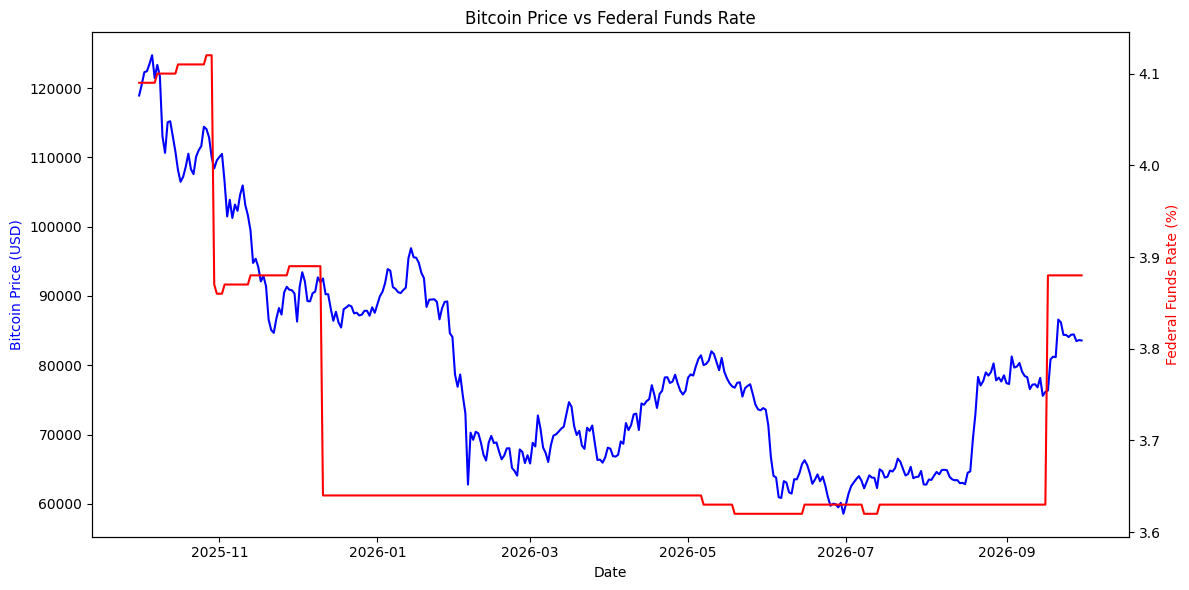

In [22]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    btc_fed["event_date"],
    btc_fed["close_price_usd"],
    color="blue"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Bitcoin Price (USD)", color="blue")

ax2 = ax1.twinx()

ax2.plot(
    btc_fed["event_date"],
    btc_fed["DFF"],
    color="red"
)

ax2.set_ylabel("Federal Funds Rate (%)", color="red")

plt.title("Bitcoin Price vs Federal Funds Rate")
fig.tight_layout()
plt.show()


In [23]:
btc_fed["btc_return"] = btc_fed["close_price_usd"].pct_change(fill_method=None) * 100

btc_fed["fed_change"] = btc_fed["DFF"].diff()

change_correlation = btc_fed["btc_return"].corr(btc_fed["fed_change"])

print("Bitcoin Returns vs Interest Rate Changes:", change_correlation)


Bitcoin Returns vs Interest Rate Changes: 0.014715755445453253


In [24]:
print("Missing Bitcoin returns:", btc_fed["btc_return"].isna().sum())

print("Missing Fed changes:", btc_fed["fed_change"].isna().sum())

print("Number of observations:", btc_fed.shape[0])


Missing Bitcoin returns: 1
Missing Fed changes: 1
Number of observations: 365


## 5. Bitcoin vs. inflation

Inflation is calculated as the 12-month percentage change in CPI and compared with Bitcoin's monthly returns. There are only 11 usable months, so this test has limited power.

In [25]:
import pandas as pd

cpi = pd.read_csv("CPIAUCSL.csv")

print(cpi.head())
print(cpi.shape)
print(cpi.columns)


  observation_date  CPIAUCSL
0       2014-10-01   237.430
1       2014-11-01   236.983
2       2014-12-01   236.252
3       2015-01-01   234.747
4       2015-02-01   235.342
(144, 2)
Index(['observation_date', 'CPIAUCSL'], dtype='object')


In [26]:
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"], utc=True)

print("First date:", cpi["observation_date"].min())
print("Last date:", cpi["observation_date"].max())
print("Total observations:", len(cpi))


First date: 2014-10-01 00:00:00+00:00
Last date: 2026-09-01 00:00:00+00:00
Total observations: 144


In [27]:
cpi = cpi.sort_values("observation_date")

cpi["inflation_rate"] = cpi["CPIAUCSL"].pct_change(periods=12, fill_method=None) * 100

print(cpi[["observation_date", "CPIAUCSL", "inflation_rate"]].tail(15))


             observation_date  CPIAUCSL  inflation_rate
129 2025-07-01 00:00:00+00:00   322.169        2.742618
130 2025-08-01 00:00:00+00:00   323.291        2.938592
131 2025-09-01 00:00:00+00:00   324.245        3.022572
132 2025-10-01 00:00:00+00:00       NaN             NaN
133 2025-11-01 00:00:00+00:00   325.063        2.696444
134 2025-12-01 00:00:00+00:00   326.031        2.653304
135 2026-01-01 00:00:00+00:00   326.588        2.391201
136 2026-02-01 00:00:00+00:00   327.460        2.434004
137 2026-03-01 00:00:00+00:00   330.293        3.285958
138 2026-04-01 00:00:00+00:00   332.407        3.779246
139 2026-05-01 00:00:00+00:00   333.979        4.166615
140 2026-06-01 00:00:00+00:00   332.568        3.463531
141 2026-07-01 00:00:00+00:00   332.813        3.303856
142 2026-08-01 00:00:00+00:00   334.131        3.353016
143 2026-09-01 00:00:00+00:00   336.298        3.717251


In [28]:
cpi_recent = cpi[
    (cpi["observation_date"] >= "2025-10-01") &
    (cpi["observation_date"] < "2026-10-01")
].copy()

print("Total months:", len(cpi_recent))

print("Missing CPI values:", cpi_recent["CPIAUCSL"].isna().sum())

print("Missing inflation rates:", cpi_recent["inflation_rate"].isna().sum())


Total months: 12
Missing CPI values: 1
Missing inflation rates: 1


In [29]:
btc_monthly = btc_filtered.copy()

btc_monthly["month"] = btc_monthly["event_date"].dt.to_period("M")

btc_monthly = btc_monthly.groupby("month")["close_price_usd"].last().reset_index()

print(btc_monthly)


      month  close_price_usd
0   2025-10    109566.606619
1   2025-11     90359.868732
2   2025-12     87575.046160
3   2026-01     78647.027398
4   2026-02     67017.076048
5   2026-03     68107.474564
6   2026-04     76296.796484
7   2026-05     73598.668124
8   2026-06     58566.091992
9   2026-07     62820.086138
10  2026-08     78552.779329
11  2026-09     83576.134600


/tmp/ipykernel_4128/1707722885.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  btc_monthly["month"] = btc_monthly["event_date"].dt.to_period("M")


In [30]:
btc_monthly["monthly_return"] = btc_monthly["close_price_usd"].pct_change(fill_method=None) * 100

print(btc_monthly)


      month  close_price_usd  monthly_return
0   2025-10    109566.606619             NaN
1   2025-11     90359.868732      -17.529737
2   2025-12     87575.046160       -3.081924
3   2026-01     78647.027398      -10.194706
4   2026-02     67017.076048      -14.787528
5   2026-03     68107.474564        1.627046
6   2026-04     76296.796484       12.024116
7   2026-05     73598.668124       -3.536359
8   2026-06     58566.091992      -20.425065
9   2026-07     62820.086138        7.263579
10  2026-08     78552.779329       25.044049
11  2026-09     83576.134600        6.394879


In [31]:
cpi_recent["month"] = cpi_recent["observation_date"].dt.to_period("M")

btc_inflation = pd.merge(
    btc_monthly,
    cpi_recent[["month", "inflation_rate"]],
    on="month",
    how="inner"
)

print(btc_inflation)


      month  close_price_usd  monthly_return  inflation_rate
0   2025-10    109566.606619             NaN             NaN
1   2025-11     90359.868732      -17.529737        2.696444
2   2025-12     87575.046160       -3.081924        2.653304
3   2026-01     78647.027398      -10.194706        2.391201
4   2026-02     67017.076048      -14.787528        2.434004
5   2026-03     68107.474564        1.627046        3.285958
6   2026-04     76296.796484       12.024116        3.779246
7   2026-05     73598.668124       -3.536359        4.166615
8   2026-06     58566.091992      -20.425065        3.463531
9   2026-07     62820.086138        7.263579        3.303856
10  2026-08     78552.779329       25.044049        3.353016
11  2026-09     83576.134600        6.394879        3.717251


/tmp/ipykernel_4128/2310200581.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  cpi_recent["month"] = cpi_recent["observation_date"].dt.to_period("M")


In [32]:
inflation_correlation = btc_inflation["monthly_return"].corr(btc_inflation["inflation_rate"])

print("Bitcoin vs Inflation Correlation:", inflation_correlation)


Bitcoin vs Inflation Correlation: 0.4483356149357381


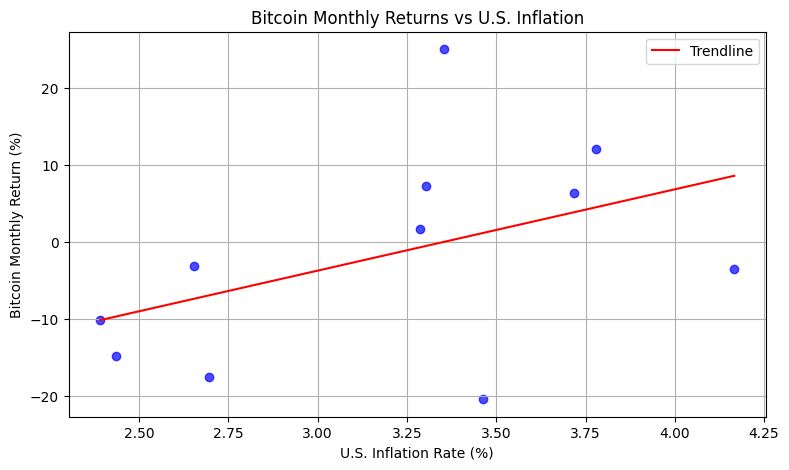

In [33]:
import numpy as np
import matplotlib.pyplot as plt

clean_inflation = btc_inflation.dropna(
    subset=["inflation_rate", "monthly_return"]
)

x = clean_inflation["inflation_rate"]
y = clean_inflation["monthly_return"]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(9, 5))

plt.scatter(x, y, color="blue", alpha=0.7)

plt.plot(
    np.sort(x),
    slope * np.sort(x) + intercept,
    color="red",
    label="Trendline"
)

plt.xlabel("U.S. Inflation Rate (%)")
plt.ylabel("Bitcoin Monthly Return (%)")
plt.title("Bitcoin Monthly Returns vs U.S. Inflation")

plt.legend()
plt.grid(True)
plt.show()


In [34]:
valid_data = btc_inflation[
    ["monthly_return", "inflation_rate"]
].dropna()

print("Number of valid observations:", len(valid_data))
print("Correlation:", valid_data["monthly_return"].corr(valid_data["inflation_rate"]))


Number of valid observations: 11
Correlation: 0.4483356149357381


In [35]:
from scipy.stats import pearsonr

correlation, p_value = pearsonr(
    valid_data["monthly_return"],
    valid_data["inflation_rate"]
)

print("Correlation:", correlation)
print("P-value:", p_value)


Correlation: 0.44833561493573804
P-value: 0.16665698921510463


## 6. Statistical significance and summary of results

In [36]:
sp500_clean = combined.dropna(
    subset=["SP500", "close_price_usd"]
).copy()

sp500_clean = sp500_clean.sort_values("event_date")

sp500_clean["btc_return"] = (
    sp500_clean["close_price_usd"].pct_change(fill_method=None) * 100
)

sp500_clean["sp500_return"] = (
    sp500_clean["SP500"].pct_change(fill_method=None) * 100
)

print("Valid return pairs:", sp500_clean[
    ["btc_return", "sp500_return"]
].dropna().shape[0])

print(sp500_clean[
    ["event_date", "btc_return", "sp500_return"]
].head(10))


Valid return pairs: 242
                 event_date  btc_return  sp500_return
0 2025-10-13 00:00:00+00:00         NaN           NaN
1 2025-10-14 00:00:00+00:00   -1.874770     -0.156430
2 2025-10-15 00:00:00+00:00   -1.965171      0.402600
3 2025-10-16 00:00:00+00:00   -2.414403     -0.629435
4 2025-10-17 00:00:00+00:00   -1.557096      0.527072
5 2025-10-20 00:00:00+00:00    3.805244      1.067225
6 2025-10-21 00:00:00+00:00   -2.021162      0.003266
7 2025-10-22 00:00:00+00:00   -0.655847     -0.533751
8 2025-10-23 00:00:00+00:00    2.340190      0.582739
9 2025-10-24 00:00:00+00:00    0.836331      0.790242


In [37]:
clean_returns = sp500_clean[
    ["btc_return", "sp500_return"]
].dropna()

clean_corr, clean_p = pearsonr(
    clean_returns["btc_return"],
    clean_returns["sp500_return"]
)

print("Valid observations:", len(clean_returns))
print("Corrected correlation:", clean_corr)
print("Corrected p-value:", clean_p)


Valid observations: 242
Corrected correlation: 0.47042850201211145
Corrected p-value: 9.931350209765319e-15


In [38]:
fed_data = btc_fed[
    ["btc_return", "fed_change"]
].dropna()

fed_corr, fed_p = pearsonr(
    fed_data["btc_return"],
    fed_data["fed_change"]
)

print("Valid observations:", len(fed_data))
print("Correlation:", fed_corr)
print("P-value:", fed_p)


Valid observations: 364
Correlation: 0.014715755445453232
P-value: 0.7796246591032852


In [39]:
results = pd.DataFrame({
    "Macroeconomic Factor": [
        "S&P 500 Returns",
        "U.S. Inflation Rate",
        "Federal Funds Rate Changes"
    ],
    "Correlation": [
        clean_corr,
        correlation,
        fed_corr
    ],
    "P-value": [
        clean_p,
        p_value,
        fed_p
    ],
    "Observations": [
        len(clean_returns),
        len(valid_data),
        len(fed_data)
    ]
})

print(results)


         Macroeconomic Factor  Correlation       P-value  Observations
0             S&P 500 Returns     0.470429  9.931350e-15           242
1         U.S. Inflation Rate     0.448336  1.666570e-01            11
2  Federal Funds Rate Changes     0.014716  7.796247e-01           364


In [40]:
results["Statistically Significant"] = results["P-value"].apply(
    lambda p: "Yes" if p < 0.05 else "No"
)

formatted_results = results.copy()

formatted_results["Correlation"] = formatted_results["Correlation"].round(4)
formatted_results["P-value"] = formatted_results["P-value"].apply(
    lambda p: f"{p:.4g}"
)

display(formatted_results)


,Macroeconomic Factor,Correlation,P-value,Observations,Statistically Significant
0,S&P 500 Returns,0.4704,9.931e-15,242,Yes
1,U.S. Inflation Rate,0.4483,0.1667,11,No
2,Federal Funds Rate Changes,0.0147,0.7796,364,No


In [41]:
formatted_results.to_csv(
    "Bitcoin_Macro_Results.csv",
    index=False
)

print("Results table saved successfully!")


Results table saved successfully!


In [42]:
print("Bitcoin missing values:")
print(btc_filtered.isna().sum())

print("\nInflation missing values:")
print(cpi_recent.isna().sum())

print("\nS&P 500 missing values:")
print(sp500.isna().sum())

print("\nFederal Funds Rate missing values:")
print(fed.isna().sum())


Bitcoin missing values:
event_date         0
close_price_usd    0
market_cap_usd     0
volume_usd         0
daily_return       1
dtype: int64

Inflation missing values:
observation_date    0
CPIAUCSL            1
inflation_rate      1
month               0
dtype: int64

S&P 500 missing values:
observation_date     0
SP500               10
dtype: int64

Federal Funds Rate missing values:
observation_date    0
DFF                 0
dtype: int64


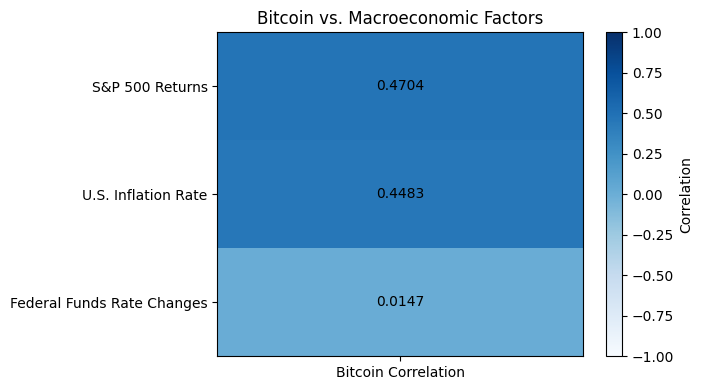

In [43]:
import matplotlib.pyplot as plt

heatmap_data = results.set_index("Macroeconomic Factor")[["Correlation"]]

fig, ax = plt.subplots(figsize=(7, 4))

image = ax.imshow(
    heatmap_data,
    cmap="Blues",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks([0])
ax.set_xticklabels(["Bitcoin Correlation"])

ax.set_yticks(range(len(heatmap_data)))
ax.set_yticklabels(heatmap_data.index)

for i in range(len(heatmap_data)):
    value = heatmap_data.iloc[i, 0]
    ax.text(0, i, f"{value:.4f}",
            ha="center", va="center")

plt.colorbar(image, ax=ax, label="Correlation")
plt.title("Bitcoin vs. Macroeconomic Factors")
plt.tight_layout()
plt.show()


In [44]:
fig.savefig(
    "Bitcoin_Macro_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

print("Heatmap saved successfully!")


Heatmap saved successfully!


In [45]:
import numpy as np

def correlation_ci(r, n):
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)

    lower = np.tanh(z - 1.96 * se)
    upper = np.tanh(z + 1.96 * se)

    return lower, upper

for index, row in results.iterrows():
    lower, upper = correlation_ci(
        row["Correlation"],
        row["Observations"]
    )

    print(row["Macroeconomic Factor"])
    print("95% Confidence Interval:", round(lower, 4), "to", round(upper, 4))
    print()


S&P 500 Returns
95% Confidence Interval: 0.366 to 0.5631

U.S. Inflation Rate
95% Confidence Interval: -0.2073 to 0.8261

Federal Funds Rate Changes
95% Confidence Interval: -0.0882 to 0.1173



## 7. Regression: Bitcoin returns on S&P 500 returns

OLS regression with Bitcoin daily returns as the dependent variable, plus HC3 robust standard errors.

In [46]:
import statsmodels.api as sm

X = clean_returns["sp500_return"]
y = clean_returns["btc_return"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())


                            OLS Regression Results                            
Dep. Variable:             btc_return   R-squared:                       0.221
Model:                            OLS   Adj. R-squared:                  0.218
Method:                 Least Squares   F-statistic:                     68.21
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           9.93e-15
Time:                        16:16:55   Log-Likelihood:                -559.22
No. Observations:                 242   AIC:                             1122.
Df Residuals:                     240   BIC:                             1129.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.1927      0.158     -1.220   

In [47]:
robust_model = model.get_robustcov_results(cov_type="HC3")

print(robust_model.summary())


                            OLS Regression Results                            
Dep. Variable:             btc_return   R-squared:                       0.221
Model:                            OLS   Adj. R-squared:                  0.218
Method:                 Least Squares   F-statistic:                     46.27
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           8.14e-11
Time:                        16:16:55   Log-Likelihood:                -559.22
No. Observations:                 242   AIC:                             1122.
Df Residuals:                     240   BIC:                             1129.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.1927      0.158     -1.219   

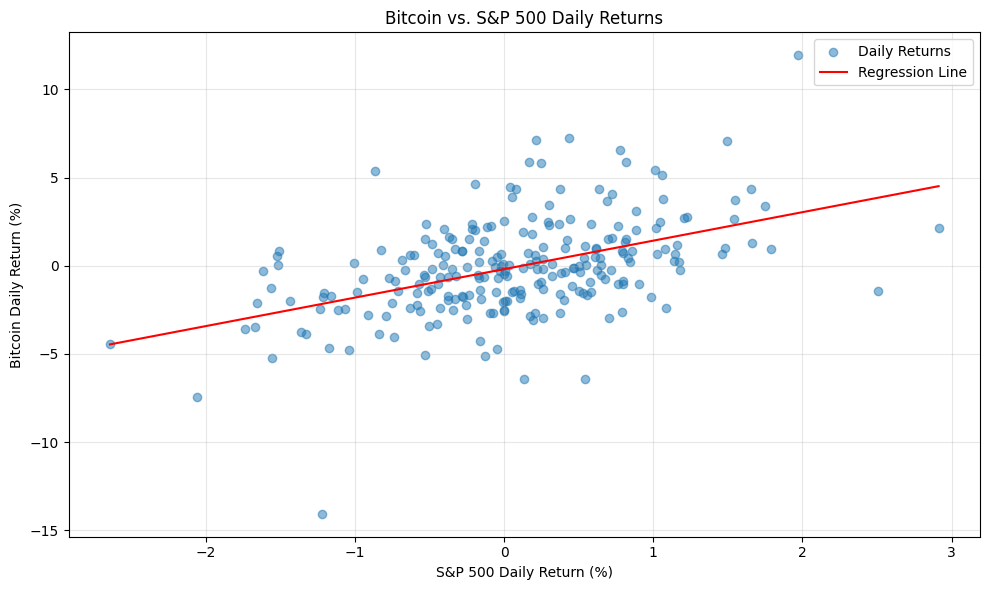

In [48]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

plt.scatter(
    clean_returns["sp500_return"],
    clean_returns["btc_return"],
    alpha=0.5,
    label="Daily Returns"
)

x_values = np.linspace(
    clean_returns["sp500_return"].min(),
    clean_returns["sp500_return"].max(),
    100
)

y_values = model.params["const"] + model.params["sp500_return"] * x_values

plt.plot(x_values, y_values, color="red", label="Regression Line")

plt.title("Bitcoin vs. S&P 500 Daily Returns")
plt.xlabel("S&P 500 Daily Return (%)")
plt.ylabel("Bitcoin Daily Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Bitcoin_SP500_Regression.png", dpi=300)
plt.show()


In [49]:
predicted_returns = model.predict()

residuals = model.resid

residual_results = clean_returns.copy()

residual_results["predicted_btc_return"] = predicted_returns
residual_results["residual"] = residuals

print(residual_results.head(10))


    btc_return  sp500_return  predicted_btc_return  residual
1    -1.874770     -0.156430             -0.445335 -1.429435
2    -1.965171      0.402600              0.457460 -2.422631
3    -2.414403     -0.629435             -1.209204 -1.205199
4    -1.557096      0.527072              0.658474 -2.215570
5     3.805244      1.067225              1.530783  2.274461
6    -2.021162      0.003266             -0.187436 -1.833726
7    -0.655847     -0.533751             -1.054681  0.398834
8     2.340190      0.582739              0.748371  1.591819
9     0.836331      0.790242              1.083475 -0.247144
10    2.751637      1.229002              1.792041  0.959596


## 8. Regression diagnostics

Residual plots and tests for heteroskedasticity (Breusch–Pagan), autocorrelation (Durbin–Watson, Breusch–Godfrey), and normality (Jarque–Bera).

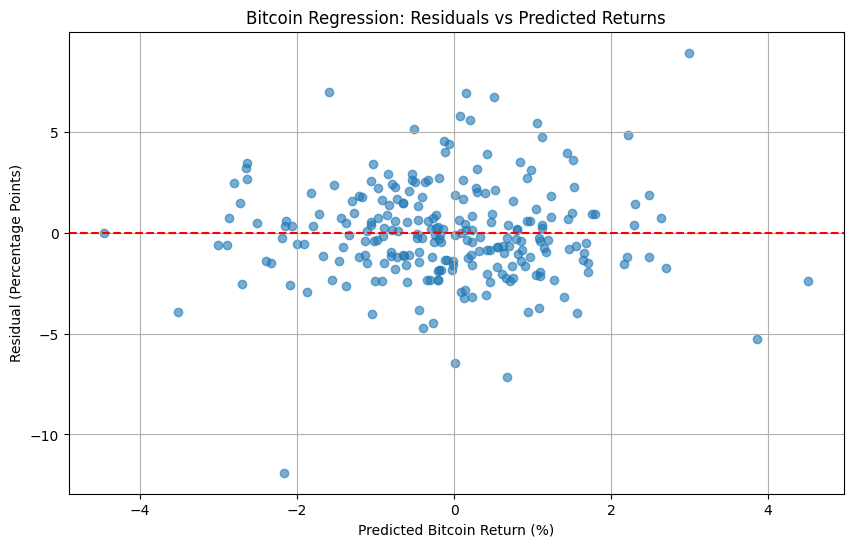

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    predicted_returns,
    residuals,
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Bitcoin Regression: Residuals vs Predicted Returns")
plt.xlabel("Predicted Bitcoin Return (%)")
plt.ylabel("Residual (Percentage Points)")

plt.grid(True)
plt.show()


In [51]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(model.resid, model.model.exog)

print("Breusch-Pagan Test")
print("LM Statistic:", bp_test[0])
print("P-value:", bp_test[1])


Breusch-Pagan Test
LM Statistic: 0.33232260995934904
P-value: 0.5642946411933092


In [52]:
from statsmodels.stats.stattools import durbin_watson

dw_stat = durbin_watson(model.resid)

print("Durbin-Watson Statistic:", dw_stat)


Durbin-Watson Statistic: 1.9112293137149043


In [53]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

bg_test = acorr_breusch_godfrey(model, nlags=5)

print("Breusch-Godfrey Test")
print("LM Statistic:", bg_test[0])
print("P-value:", bg_test[1])


Breusch-Godfrey Test
LM Statistic: 4.925857879364068
P-value: 0.4249955172073715


/tmp/ipykernel_4128/2234634093.py:3: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(model, nlags=5)


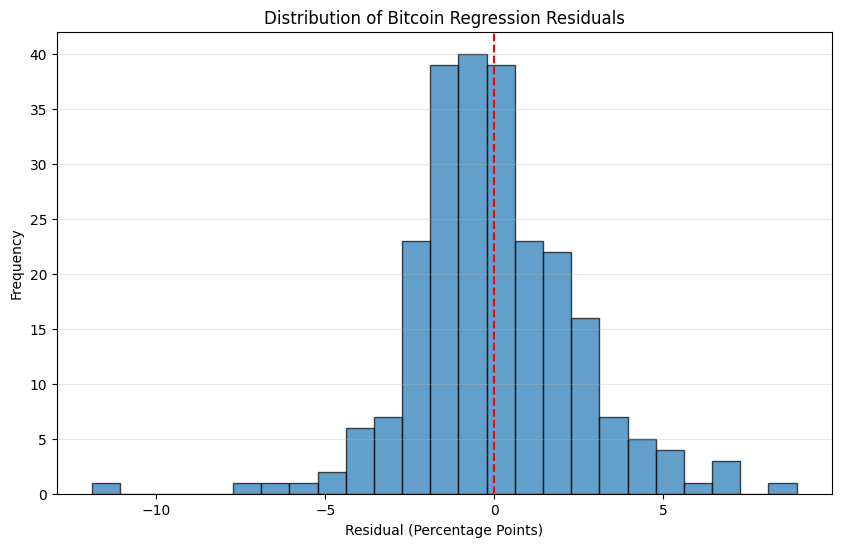

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    residuals,
    bins=25,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Bitcoin Regression Residuals")
plt.xlabel("Residual (Percentage Points)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.show()


In [55]:
from scipy.stats import jarque_bera, skew, kurtosis

jb_stat, jb_p = jarque_bera(residuals)

print("Jarque-Bera Test")
print("JB Statistic:", jb_stat)
print("P-value:", jb_p)

print("Skewness:", skew(residuals))
print("Excess Kurtosis:", kurtosis(residuals))


Jarque-Bera Test
JB Statistic: 83.60892838794285
P-value: 6.991202499943393e-19
Skewness: 0.013335422442197976
Excess Kurtosis: 2.879424112023708


## 9. Outliers and sensitivity

February 5 and 6, 2026 stand out because Bitcoin fell sharply and then rebounded. I use Cook's Distance to check whether a small number of unusual days are driving the regression, then compare the results after excluding observations above the screening threshold.

In [56]:
largest_errors = residual_results.copy()

largest_errors["absolute_residual"] = largest_errors["residual"].abs()

largest_errors = largest_errors.sort_values(
    "absolute_residual",
    ascending=False
)

print(largest_errors.head(10))


     btc_return  sp500_return  predicted_btc_return   residual  \
83   -14.072102     -1.225097             -2.171156 -11.900946   
84    11.937747      1.969581              2.988024   8.949723   
80    -6.446588      0.539124              0.677937  -7.124525   
223    5.383000     -0.866894             -1.592683   6.975683   
222    7.118595      0.210875              0.147838   6.970757   
224    7.253852      0.434620              0.509170   6.744682   
166   -6.440003      0.129211              0.015956  -6.455959   
244    5.895169      0.166803              0.076664   5.818505   
36     5.812231      0.245720              0.204110   5.608121   
102    6.538299      0.775603              1.059834   5.478465   

     absolute_residual  
83           11.900946  
84            8.949723  
80            7.124525  
223           6.975683  
222           6.970757  
224           6.744682  
166           6.455959  
244           5.818505  
36            5.608121  
102           5.478465 

In [57]:
influence = model.get_influence()

cooks_distance = influence.cooks_distance[0]

influence_results = residual_results.copy()
influence_results["cooks_distance"] = cooks_distance

influence_results = influence_results.sort_values(
    "cooks_distance",
    ascending=False
)

print(influence_results.head(10))

threshold = 4 / len(influence_results)

print("Cook's Distance threshold:", threshold)
print(
    "Observations above threshold:",
    (influence_results["cooks_distance"] > threshold).sum()
)


     btc_return  sp500_return  predicted_btc_return   residual  cooks_distance
84    11.937747      1.969581              2.988024   8.949723        0.192825
83   -14.072102     -1.225097             -2.171156 -11.900946        0.178260
127   -1.419124      2.508142              3.857762  -5.276887        0.106939
71    -7.439345     -2.062677             -3.523789  -3.915556        0.044872
223    5.383000     -0.866894             -1.592683   6.975683        0.039742
245    7.076671      1.492713              2.217916   4.858755        0.035003
121    2.123521      2.913117              4.511769  -2.388248        0.029833
80    -6.446588      0.539124              0.677937  -7.124525        0.023899
114    0.843755     -1.513814             -2.637414   3.481169        0.020947
224    7.253852      0.434620              0.509170   6.744682        0.019223
Cook's Distance threshold: 0.01652892561983471
Observations above threshold: 13


In [58]:
import statsmodels.api as sm

less_influential = influence_results[
    influence_results["cooks_distance"] <= threshold
].copy()

X_new = less_influential[["sp500_return"]]
y_new = less_influential["btc_return"]

X_new = sm.add_constant(X_new)

sensitivity_model = sm.OLS(y_new, X_new).fit(cov_type="HC3")

print("Original regression coefficient:",
      model.params["sp500_return"])

print("Sensitivity regression coefficient:",
      sensitivity_model.params["sp500_return"])

print("Original R-squared:", model.rsquared)

print("Sensitivity R-squared:", sensitivity_model.rsquared)

print("Remaining observations:", len(less_influential))


Original regression coefficient: 1.6149295947980076
Sensitivity regression coefficient: 1.492745936922581
Original R-squared: 0.22130297550535905
Sensitivity R-squared: 0.23571739334092856
Remaining observations: 229


## 10. Newey–West (HAC) robust standard errors

In [59]:
# Newey-West (HAC) robust regression

hac_model = model.get_robustcov_results(
    cov_type="HAC",
    maxlags=5
)

print(hac_model.summary())


                            OLS Regression Results                            
Dep. Variable:             btc_return   R-squared:                       0.221
Model:                            OLS   Adj. R-squared:                  0.218
Method:                 Least Squares   F-statistic:                     37.20
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           4.23e-09
Time:                        16:16:56   Log-Likelihood:                -559.22
No. Observations:                 242   AIC:                             1122.
Df Residuals:                     240   BIC:                             1129.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.1927      0.178     -1.081   

In [60]:
# Compare HC3 and HAC confidence intervals

print("HC3 Confidence Interval:")
print(robust_model.conf_int()[1])

print("\nHAC Confidence Interval:")
print(hac_model.conf_int()[1])


HC3 Confidence Interval:
[1.14725389 2.0826053 ]

HAC Confidence Interval:
[1.093353   2.13650619]


## 11. In-sample model fit

In [61]:
import numpy as np

actual_returns = np.asarray(model.model.endog)

predicted_returns = np.asarray(model.fittedvalues)

errors = actual_returns - predicted_returns

mae = np.mean(np.abs(errors))

rmse = np.sqrt(np.mean(errors ** 2))

r_squared = model.rsquared
adjusted_r_squared = model.rsquared_adj

print("Bitcoin Regression Model Evaluation")
print("-----------------------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R-squared:", round(r_squared, 4))
print("Adjusted R-squared:", round(adjusted_r_squared, 4))


Bitcoin Regression Model Evaluation
-----------------------------------
MAE: 1.7925
RMSE: 2.4398
R-squared: 0.2213
Adjusted R-squared: 0.2181


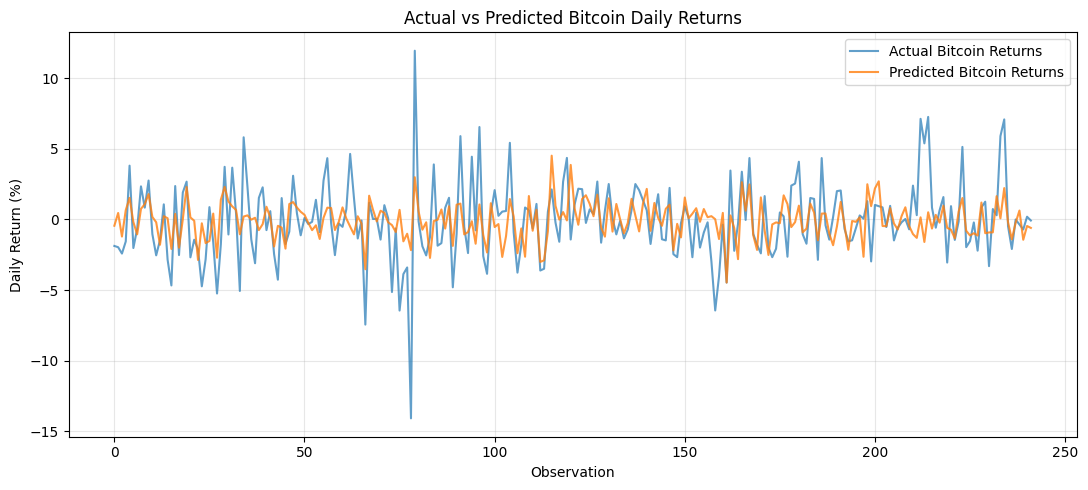

In [62]:
# Actual vs Predicted Bitcoin Returns

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(actual_returns, label="Actual Bitcoin Returns", alpha=0.7)
plt.plot(predicted_returns, label="Predicted Bitcoin Returns", alpha=0.8)

plt.title("Actual vs Predicted Bitcoin Daily Returns")
plt.xlabel("Observation")
plt.ylabel("Daily Return (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Bitcoin_Actual_vs_Predicted.png", dpi=300)
plt.show()


## 12. Out-of-sample test

I split the observations in time order (80% training, 20% testing) and compare the regression with a simple baseline: the average Bitcoin return from the training period. Because the model uses the **same day's** S&P 500 return, this is a check on how well the relationship generalizes, **not** a practical advance forecast or trading strategy.

In [63]:
data = clean_returns[
    ["btc_return", "sp500_return"]
].dropna().copy()

split_index = int(len(data) * 0.80)

train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

print("Total observations:", len(data))
print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining sample:")
print(train_data.head())

print("\nTesting sample:")
print(test_data.head())


Total observations: 242
Training observations: 193
Testing observations: 49

Training sample:
   btc_return  sp500_return
1   -1.874770     -0.156430
2   -1.965171      0.402600
3   -2.414403     -0.629435
4   -1.557096      0.527072
5    3.805244      1.067225

Testing sample:
     btc_return  sp500_return
203   -1.550583     -1.208968
204   -1.475469      0.049674
205   -0.610514      0.016190
206    0.283495      0.210436
207    0.054248     -1.516131


In [64]:
import statsmodels.api as sm

X_train = train_data[["sp500_return"]]

y_train = train_data["btc_return"]

X_train = sm.add_constant(X_train)

train_model = sm.OLS(y_train, X_train).fit(cov_type="HC3")

print(train_model.summary())


                            OLS Regression Results                            
Dep. Variable:             btc_return   R-squared:                       0.253
Model:                            OLS   Adj. R-squared:                  0.249
Method:                 Least Squares   F-statistic:                     41.37
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           9.85e-10
Time:                        16:16:57   Log-Likelihood:                -444.98
No. Observations:                 193   AIC:                             894.0
Df Residuals:                     191   BIC:                             900.5
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.3597      0.177     -2.038   

In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_test = test_data[["sp500_return"]]
y_test = test_data["btc_return"]

X_test = sm.add_constant(X_test, has_constant="add")

test_predictions = train_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print("Out-of-Sample Model Evaluation")
print("------------------------------")
print("Testing observations:", len(y_test))
print("Testing MAE:", round(test_mae, 4))
print("Testing RMSE:", round(test_rmse, 4))


Out-of-Sample Model Evaluation
------------------------------
Testing observations: 49
Testing MAE: 1.7032
Testing RMSE: 2.5209


In [66]:
# Baseline predicts the training-period average BTC return
baseline_prediction = y_train.mean()

baseline_predictions = np.full(
    len(y_test),
    baseline_prediction
)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Out-of-Sample Model Comparison")
print("--------------------------------")
print("Regression MAE:", round(test_mae, 4))
print("Baseline MAE:", round(baseline_mae, 4))
print()
print("Regression RMSE:", round(test_rmse, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))


Out-of-Sample Model Comparison
--------------------------------
Regression MAE: 1.7032
Baseline MAE: 1.6949

Regression RMSE: 2.5209
Baseline RMSE: 2.6096


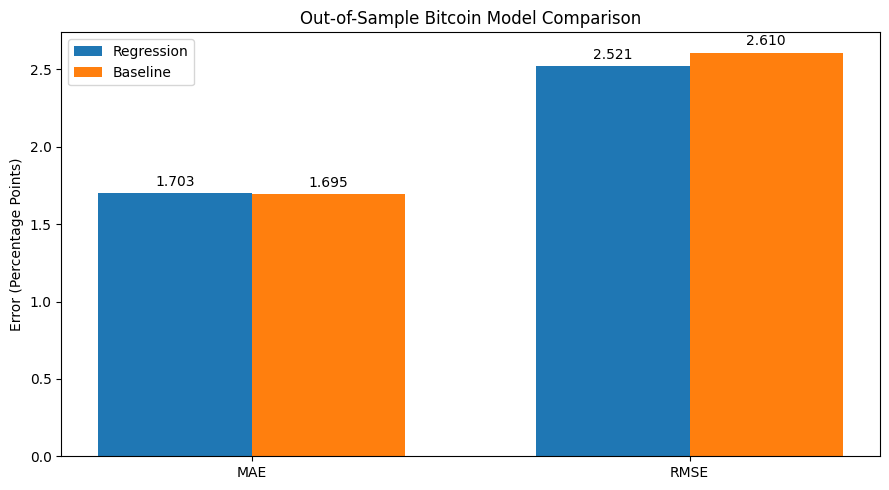

In [67]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["MAE", "RMSE"]
regression = [test_mae, test_rmse]
baseline = [baseline_mae, baseline_rmse]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, regression, width, label="Regression")
bars2 = ax.bar(x + width/2, baseline, width, label="Baseline")

ax.set_title("Out-of-Sample Bitcoin Model Comparison")
ax.set_ylabel("Error (Percentage Points)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig("Bitcoin_Model_Comparison.png", dpi=300)
plt.show()


## 13. Robustness check: return alignment

For the main model, I calculate Bitcoin returns between matched S&P 500 trading dates. Here I try a different approach: calculate Bitcoin's calendar-day returns first, then match the dates. This checks whether the main finding depends on how I line up the two markets.

In [68]:
import pandas as pd
import statsmodels.api as sm

original = clean_returns[
    ["btc_return", "sp500_return"]
].dropna().copy()

original_corr = original["btc_return"].corr(
    original["sp500_return"]
)

original_model = sm.OLS(
    original["btc_return"],
    sm.add_constant(original["sp500_return"])
).fit()

btc_alt = pd.read_csv("btc-usd-max.csv")
sp_alt = pd.read_csv("SP500.csv")

btc_alt["event_date"] = pd.to_datetime(
    btc_alt["event_date"], utc=True
).dt.tz_localize(None).dt.normalize()

sp_alt["observation_date"] = pd.to_datetime(
    sp_alt["observation_date"], utc=True
).dt.tz_localize(None).dt.normalize()

btc_alt["close_price_usd"] = pd.to_numeric(
    btc_alt["close_price_usd"], errors="coerce"
)

sp_alt["SP500"] = pd.to_numeric(
    sp_alt["SP500"], errors="coerce"
)

btc_alt = btc_alt.sort_values("event_date")
sp_alt = sp_alt.sort_values("observation_date")

btc_alt["btc_return"] = (
    btc_alt["close_price_usd"].pct_change(
        fill_method=None
    ) * 100
)

sp_alt["sp500_return"] = (
    sp_alt["SP500"].pct_change(
        fill_method=None
    ) * 100
)

alternative = pd.merge(
    btc_alt[["event_date", "btc_return"]],
    sp_alt[["observation_date", "sp500_return"]],
    left_on="event_date",
    right_on="observation_date",
    how="inner"
)

start_date = pd.Timestamp("2025-10-01")
end_date = pd.Timestamp("2026-09-30")

alternative = alternative[
    (alternative["event_date"] >= start_date) &
    (alternative["event_date"] <= end_date)
].dropna().copy()

alternative_corr = alternative["btc_return"].corr(
    alternative["sp500_return"]
)

alternative_model = sm.OLS(
    alternative["btc_return"],
    sm.add_constant(alternative["sp500_return"])
).fit()

print("RETURN ALIGNMENT ROBUSTNESS CHECK")
print("-----------------------------------")

print("Original correlation:",
      round(original_corr, 4))

print("Original R-squared:",
      round(original_model.rsquared, 4))

print("Alternative correlation:",
      round(alternative_corr, 4))

print("Alternative R-squared:",
      round(alternative_model.rsquared, 4))

print("Original observations:", len(original))
print("Alternative observations:", len(alternative))

print("-----------------------------------")
print("Alternative sample start:",
      alternative["event_date"].min())

print("Alternative sample end:",
      alternative["event_date"].max())


RETURN ALIGNMENT ROBUSTNESS CHECK
-----------------------------------
Original correlation: 0.4704
Original R-squared: 0.2213
Alternative correlation: 0.4392
Alternative R-squared: 0.1929
Original observations: 242
Alternative observations: 232
-----------------------------------
Alternative sample start: 2025-10-14 00:00:00
Alternative sample end: 2026-09-30 00:00:00


## Conclusion

- **H1 supported:** Bitcoin and S&P 500 daily returns had a correlation of about 0.47. On average Bitcoin moved about 1.6% for every 1% move in the S&P 500 (R² ≈ 0.22). The result held with robust standard errors, after removing outliers, and under the alternative alignment method.
- **H2 not supported:** essentially no correlation with daily Fed funds rate changes (0.01, p = 0.78), largely because the effective rate rarely moves day to day.
- **H3 not supported:** a correlation of 0.45 with inflation, but not significant (p = 0.17, n = 11).
- Out of sample, the regression did not clearly beat a simple historical-average baseline.

**Next steps:** test a one-day lag between the S&P 500 and Bitcoin, look at FOMC announcement days, and use CPI release dates and inflation surprises.